In [1]:
import os
import glob
import numpy as np
import nibabel as nib
from tqdm.auto import tqdm

# Update if running notebook from a different working directory
DATA_DIR = "/home/23bq1a4293/Personal/project/seg_data/pit_adv"

t1_files = sorted(glob.glob(os.path.join(DATA_DIR, "*_T1.nii.gz")))
print(f"Total T1 Scans Found: {len(t1_files)}")

# Sample 25 cases across the cohort for fast, statistically sound profiling
sample_files = t1_files[::max(1, len(t1_files) // 25)]

tumor_bboxes = []
tumor_volumes_cc = []
carotid_volumes_cc = []
overlap_count = 0
intensities_p05, intensities_p99 = [], []
crop_ratios = []
spacings = []

for t1_p in tqdm(sample_files, desc="Profiling Pituitary Dataset"):
    pid = os.path.basename(t1_p).replace("_T1.nii.gz", "")
    tum_p = os.path.join(DATA_DIR, f"{pid}_tumor_f.nii.gz")
    car_p = os.path.join(DATA_DIR, f"{pid}_carotids_f.nii.gz")
    
    if not os.path.exists(tum_p):
        continue
        
    t1_img = nib.load(t1_p)
    t1_data = t1_img.get_fdata()
    zooms = t1_img.header.get_zooms()
    spacings.append(zooms)
    voxel_vol_cc = np.prod(zooms) / 1000.0  # mm^3 to cm^3 (cc)
    
    # 1. Non-zero brain intensity percentiles
    brain_voxels = t1_data[t1_data > 10]
    if len(brain_voxels) > 0:
        intensities_p05.append(np.percentile(brain_voxels, 0.5))
        intensities_p99.append(np.percentile(brain_voxels, 99.5))
    
    # 2. Tumor volume and bounding box
    tum_data = (nib.load(tum_p).get_fdata() > 0.5).astype(np.uint8)
    tum_voxels = np.sum(tum_data)
    tumor_volumes_cc.append(tum_voxels * voxel_vol_cc)
    
    if tum_voxels > 0:
        pos = np.where(tum_data)
        bbox = [int(np.max(p) - np.min(p) + 1) for p in pos]
        tumor_bboxes.append(bbox)
        
    # 3. Carotid artery check & mutual overlap
    if os.path.exists(car_p):
        car_data = (nib.load(car_p).get_fdata() > 0.5).astype(np.uint8)
        car_voxels = np.sum(car_data)
        carotid_volumes_cc.append(car_voxels * voxel_vol_cc)
        if np.sum(tum_data & car_data) > 0:
            overlap_count += 1
            
    # 4. Measure dead air / background ratio
    brain_mask = t1_data > (np.mean(t1_data) * 0.1)
    crop_ratios.append(np.sum(brain_mask) / t1_data.size)

tumor_bboxes = np.array(tumor_bboxes)

print("\n" + "=" * 65)
print("            PITUITARY 3D DATASET PROFILING SUMMARY")
print("=" * 65)
print(f"Cohort Analyzed            : {len(sample_files)} sample scans")
print(f"Voxel Spacing (mm)         : Median {np.median(spacings, axis=0)}")
print(f"Tumor Volume (cc)          : Min {np.min(tumor_volumes_cc):.2f} | Median {np.median(tumor_volumes_cc):.2f} | Max {np.max(tumor_volumes_cc):.2f}")
print(f"Carotid Volume (cc)        : Median {np.median(carotid_volumes_cc):.2f}")
print(f"Tumor Bounding Box (voxels):")
print(f"  - Dim 0 (Sagittal)       : Min {np.min(tumor_bboxes[:, 0])} | Median {int(np.median(tumor_bboxes[:, 0]))} | Max {np.max(tumor_bboxes[:, 0])}")
print(f"  - Dim 1 (Coronal)        : Min {np.min(tumor_bboxes[:, 1])} | Median {int(np.median(tumor_bboxes[:, 1]))} | Max {np.max(tumor_bboxes[:, 1])}")
print(f"  - Dim 2 (Axial)          : Min {np.min(tumor_bboxes[:, 2])} | Median {int(np.median(tumor_bboxes[:, 2]))} | Max {np.max(tumor_bboxes[:, 2])}")
print(f"Intensity Bounds (0.5%-99%): [{np.median(intensities_p05):.1f}, {np.median(intensities_p99):.1f}]")
print(f"Tumor-Carotid Overlap      : {overlap_count} / {len(sample_files)} cases have direct abutment/overlap")
print(f"Brain Volume Ratio         : Brain occupies {np.median(crop_ratios)*100:.1f}% of volume")
print(f"RAM Saved by CropForeground: {100 - np.median(crop_ratios)*100:.1f}% memory reduction")
print("=" * 65)

/usr/local/pythonEnv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.1.0)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(


Total T1 Scans Found: 136


Profiling Pituitary Dataset:   0%|          | 0/28 [00:00<?, ?it/s]


            PITUITARY 3D DATASET PROFILING SUMMARY
Cohort Analyzed            : 28 sample scans
Voxel Spacing (mm)         : Median [0.5 0.5 0.5]
Tumor Volume (cc)          : Min 0.72 | Median 4.09 | Max 27.59
Carotid Volume (cc)        : Median 1.43
Tumor Bounding Box (voxels):
  - Dim 0 (Sagittal)       : Min 30 | Median 46 | Max 95
  - Dim 1 (Coronal)        : Min 25 | Median 41 | Max 96
  - Dim 2 (Axial)          : Min 20 | Median 47 | Max 103
Intensity Bounds (0.5%-99%): [10.1, 578.5]
Tumor-Carotid Overlap      : 0 / 28 cases have direct abutment/overlap
Brain Volume Ratio         : Brain occupies 55.3% of volume
RAM Saved by CropForeground: 44.7% memory reduction


In [1]:
# Save as: preprocess_pit_1mm.py
import os
import glob
import time
import torch
import nibabel as nib
import numpy as np
from tqdm import tqdm

import monai
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Spacingd,
    CropForegroundd,
    NormalizeIntensityd,
    EnsureTyped,
    MapTransform,
)

DATA_DIR = "/home/23bq1a4293/Personal/project/seg_data/pit_adv"
OUT_DIR = os.path.join(DATA_DIR, "processed_1mm")
os.makedirs(OUT_DIR, exist_ok=True)

class MergeMasksd(MapTransform):
    def __call__(self, data):
        d = dict(data)
        tumor = d.pop("tumor")
        carotids = d.pop("carotids")
        has_car = d.pop("has_carotids", True)
        
        label = torch.zeros_like(tumor, dtype=torch.int64)
        label[tumor > 0.5] = 1
        if has_car:
            label[carotids > 0.5] = 2
        d["label"] = label
        return d

t1_files = sorted(glob.glob(os.path.join(DATA_DIR, "*_T1.nii.gz")))
valid_files = []

for t1 in t1_files:
    pid = os.path.basename(t1).replace("_T1.nii.gz", "")
    tum = os.path.join(DATA_DIR, f"{pid}_tumor_f.nii.gz")
    car = os.path.join(DATA_DIR, f"{pid}_carotids_f.nii.gz")
    if os.path.exists(tum):
        valid_files.append({
            "image": t1,
            "tumor": tum,
            "carotids": car if os.path.exists(car) else tum,
            "has_carotids": os.path.exists(car),
            "pid": pid,
        })

print(f"[{time.strftime('%X')}] Preprocessing {len(valid_files)} subjects to 1.0mm isotropic...", flush=True)

pipeline = Compose([
    LoadImaged(keys=["image", "tumor", "carotids"]),
    EnsureChannelFirstd(keys=["image", "tumor", "carotids"]),
    MergeMasksd(keys=["tumor", "carotids"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Spacingd(keys=["image", "label"], pixdim=(1.0, 1.0, 1.0), mode=("bilinear", "nearest")),
    CropForegroundd(keys=["image", "label"], source_key="image", select_fn=lambda x: x > 10, margin=8),
    NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
    EnsureTyped(keys=["image", "label"], dtype=[torch.float32, torch.int64]),
])

for item in tqdm(valid_files, desc="Resampling to 1.0mm"):
    pid = item["pid"]
    out_file = os.path.join(OUT_DIR, f"{pid}.pt")
    if not os.path.exists(out_file):
        processed = pipeline(item)
        torch.save({
            "image": processed["image"].clone(),
            "label": processed["label"].clone(),
            "pid": pid,
        }, out_file)

print(f"[{time.strftime('%X')}] Done! All 1.0mm volumes saved to {OUT_DIR}", flush=True)

/usr/local/pythonEnv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.1.0)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(
I0000 00:00:1793760285.399280  337123 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793760285.484793  337123 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793760287.246350  337123 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different 

[08:14:47] Preprocessing 135 subjects to 1.0mm isotropic...


/usr/local/pythonEnv/lib/python3.12/site-packages/monai/utils/deprecate_utils.py:321: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)
Resampling to 1.0mm: 100%|██████████| 135/135 [00:00<00:00, 115510.21it/s]

[08:14:47] Done! All 1.0mm volumes saved to /home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_1mm


In [2]:
!ls -lh /home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_1mm | head -n 5

total 16G
-rw-r--r-- 1 23bq1a4293 1018 146M Nov  4 07:38 100.pt
-rw-r--r-- 1 23bq1a4293 1018 121M Nov  4 07:38 101.pt
-rw-r--r-- 1 23bq1a4293 1018 121M Nov  4 07:38 102.pt
-rw-r--r-- 1 23bq1a4293 1018 105M Nov  4 07:38 103.pt


I0000 00:00:1793764381.785018  668032 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793764381.870488  668032 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793764385.435367  668032 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/tmp/ipykernel_668032/1989609611.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current de

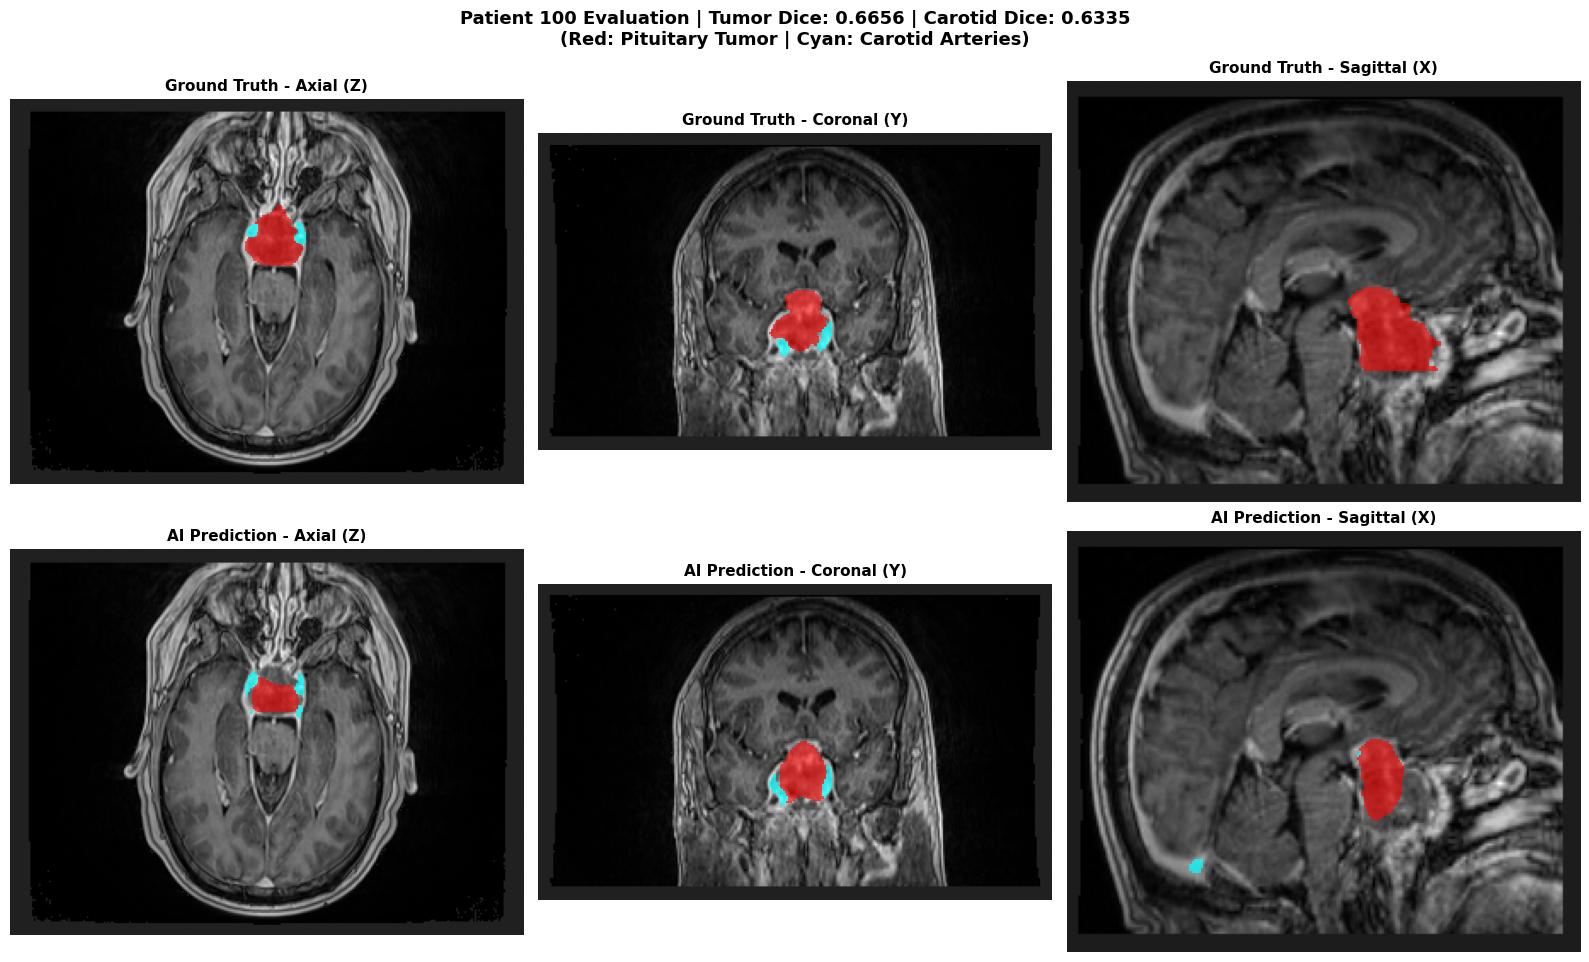

Saved side-by-side visualization to: pituitary_ai_vs_groundtruth.png


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference

PID = "100"  # Pick any patient ID from processed_1mm/
DATA_PATH = f"/home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_1mm/{PID}.pt"
MODEL_PATH = "/home/23bq1a4293/Personal/project/seg_data/pit_adv/pituitary_3d_output_1mm/best_pituitary_segresnet_1mm.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load Preprocessed 1.0mm Volume
data = torch.load(DATA_PATH, map_location="cpu")
image = data["image"].unsqueeze(0).to(device)  # [1, 1, D, H, W]
label = data["label"].unsqueeze(0).to(device)  # [1, 1, D, H, W]

# 2. Load Trained SegResNet Checkpoint
model = SegResNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=3,
    init_filters=16,
    blocks_down=[1, 2, 2, 4],
    blocks_up=[1, 1, 1],
    dropout_prob=0.2,
).to(device)

checkpoint = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# 3. Sliding Window 3D Inference
with torch.inference_mode():
    outputs = sliding_window_inference(
        inputs=image,
        roi_size=(128, 128, 128),
        sw_batch_size=2,
        predictor=model,
        overlap=0.5,
        mode="gaussian",
    )
    pred = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

gt = label.squeeze().cpu().numpy()
raw_img = image.squeeze().cpu().numpy()

# 4. Compute Patient-Specific Dice Scores
pred_tum, gt_tum = (pred == 1), (gt == 1)
tum_dice = (2.0 * np.sum(pred_tum & gt_tum)) / (np.sum(pred_tum) + np.sum(gt_tum) + 1e-6)

pred_car, gt_car = (pred == 2), (gt == 2)
car_dice = (2.0 * np.sum(pred_car & gt_car)) / (np.sum(pred_car) + np.sum(gt_car) + 1e-6)

# Find Center of Tumor
coords = np.where(gt_tum)
if len(coords[0]) > 0:
    cx, cy, cz = int(np.mean(coords[0])), int(np.mean(coords[1])), int(np.mean(coords[2]))
else:
    cx, cy, cz = [s // 2 for s in raw_img.shape]

# 5. Plot Comparison (Top: Ground Truth, Bottom: AI Predicted)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

views = [
    ("Axial (Z)", np.rot90(raw_img[:, :, cz]), np.rot90(gt[:, :, cz]), np.rot90(pred[:, :, cz])),
    ("Coronal (Y)", np.rot90(raw_img[:, cy, :]), np.rot90(gt[:, cy, :]), np.rot90(pred[:, cy, :])),
    ("Sagittal (X)", np.rot90(raw_img[cx, :, :]), np.rot90(gt[cx, :, :]), np.rot90(pred[cx, :, :])),
]

for col, (title, img_slice, gt_slice, pred_slice) in enumerate(views):
    # Top Row: Ground Truth
    axes[0, col].imshow(img_slice, cmap="gray")
    axes[0, col].imshow(np.ma.masked_where(gt_slice != 1, gt_slice), cmap="autumn", alpha=0.6, interpolation="none")
    axes[0, col].imshow(np.ma.masked_where(gt_slice != 2, gt_slice), cmap="cool", alpha=0.7, interpolation="none")
    axes[0, col].set_title(f"Ground Truth - {title}", fontsize=11, fontweight="bold")
    axes[0, col].axis("off")
    
    # Bottom Row: AI Prediction
    axes[1, col].imshow(img_slice, cmap="gray")
    axes[1, col].imshow(np.ma.masked_where(pred_slice != 1, pred_slice), cmap="autumn", alpha=0.6, interpolation="none")
    axes[1, col].imshow(np.ma.masked_where(pred_slice != 2, pred_slice), cmap="cool", alpha=0.7, interpolation="none")
    axes[1, col].set_title(f"AI Prediction - {title}", fontsize=11, fontweight="bold")
    axes[1, col].axis("off")

plt.suptitle(
    f"Patient {PID} Evaluation | Tumor Dice: {tum_dice:.4f} | Carotid Dice: {car_dice:.4f}\n"
    f"(Red: Pituitary Tumor | Cyan: Carotid Arteries)",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.savefig("pituitary_ai_vs_groundtruth.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved side-by-side visualization to: pituitary_ai_vs_groundtruth.png")

In [2]:
import os
import glob
import torch
import numpy as np
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference
from monai.transforms import KeepLargestConnectedComponent

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/home/23bq1a4293/Personal/project/seg_data/pit_adv/pituitary_3d_output_gold/best_pituitary_gold_3d.pth"
PROCESSED_DIR = "/home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_1mm"

model = SegResNet(
    spatial_dims=3, in_channels=1, out_channels=3,
    init_filters=32, blocks_down=[1, 2, 2, 4], blocks_up=[1, 1, 1], dropout_prob=0.2
).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=False))
model.eval()

all_files = sorted(glob.glob(os.path.join(PROCESSED_DIR, "*.pt")))
torch.manual_seed(42)
perm = torch.randperm(len(all_files)).tolist()
val_files = [all_files[i] for i in perm[108:]]

def calc_dice(p, g):
    inter = (p * g).sum().item()
    tot = (p.sum() + g.sum()).item()
    return (2.0 * inter) / (tot + 1e-5) if tot > 0 else 1.0

clean_tumor = KeepLargestConnectedComponent(applied_labels=[1], num_components=1)
clean_carotid = KeepLargestConnectedComponent(applied_labels=[2], num_components=2)

def predict_tta(img):
    """Test-Time Augmentation over 4 spatial orientations with overlap=0.75"""
    flips = [
        [],
        [2],     # flip axial
        [3],     # flip coronal
        [4]      # flip sagittal
    ]
    prob_accum = torch.zeros((1, 3, *img.shape[2:]), device=device)
    
    for dims in flips:
        x = torch.flip(img, dims=dims) if dims else img
        logits = sliding_window_inference(x, (128, 128, 128), 1, model, overlap=0.75, mode="gaussian")
        probs = torch.softmax(logits, dim=1)
        if dims:
            probs = torch.flip(probs, dims=dims)
        prob_accum += probs
        
    return prob_accum / len(flips)

tta_tumor, tta_carotid = [], []
print("Evaluating all 27 cases with TTA + 0.75 Overlap...")
with torch.inference_mode():
    for f in val_files:
        data = torch.load(f, map_location="cpu", weights_only=False)
        img = data["image"].unsqueeze(0).to(device)
        gt = data["label"].unsqueeze(0)

        avg_probs = predict_tta(img)
        pred = torch.argmax(avg_probs, dim=1, keepdim=True).cpu()

        cleaned = clean_carotid(clean_tumor(pred))
        tta_tumor.append(calc_dice((cleaned == 1).float(), (gt == 1).float()))
        tta_carotid.append(calc_dice((cleaned == 2).float(), (gt == 2).float()))

print("=" * 65)
print(f"WITH TTA + 0.75 OVERLAP -> Tumor: {np.mean(tta_tumor):.4f} | Carotids: {np.mean(tta_carotid):.4f} | Mean: {(np.mean(tta_tumor)+np.mean(tta_carotid))/2:.4f}")
print("=" * 65)

Evaluating all 27 cases with TTA + 0.75 Overlap...


WITH TTA + 0.75 OVERLAP -> Tumor: 0.7502 | Carotids: 0.6476 | Mean: 0.6989


Saved visualization to pituitary_gold_80ep_visual.png


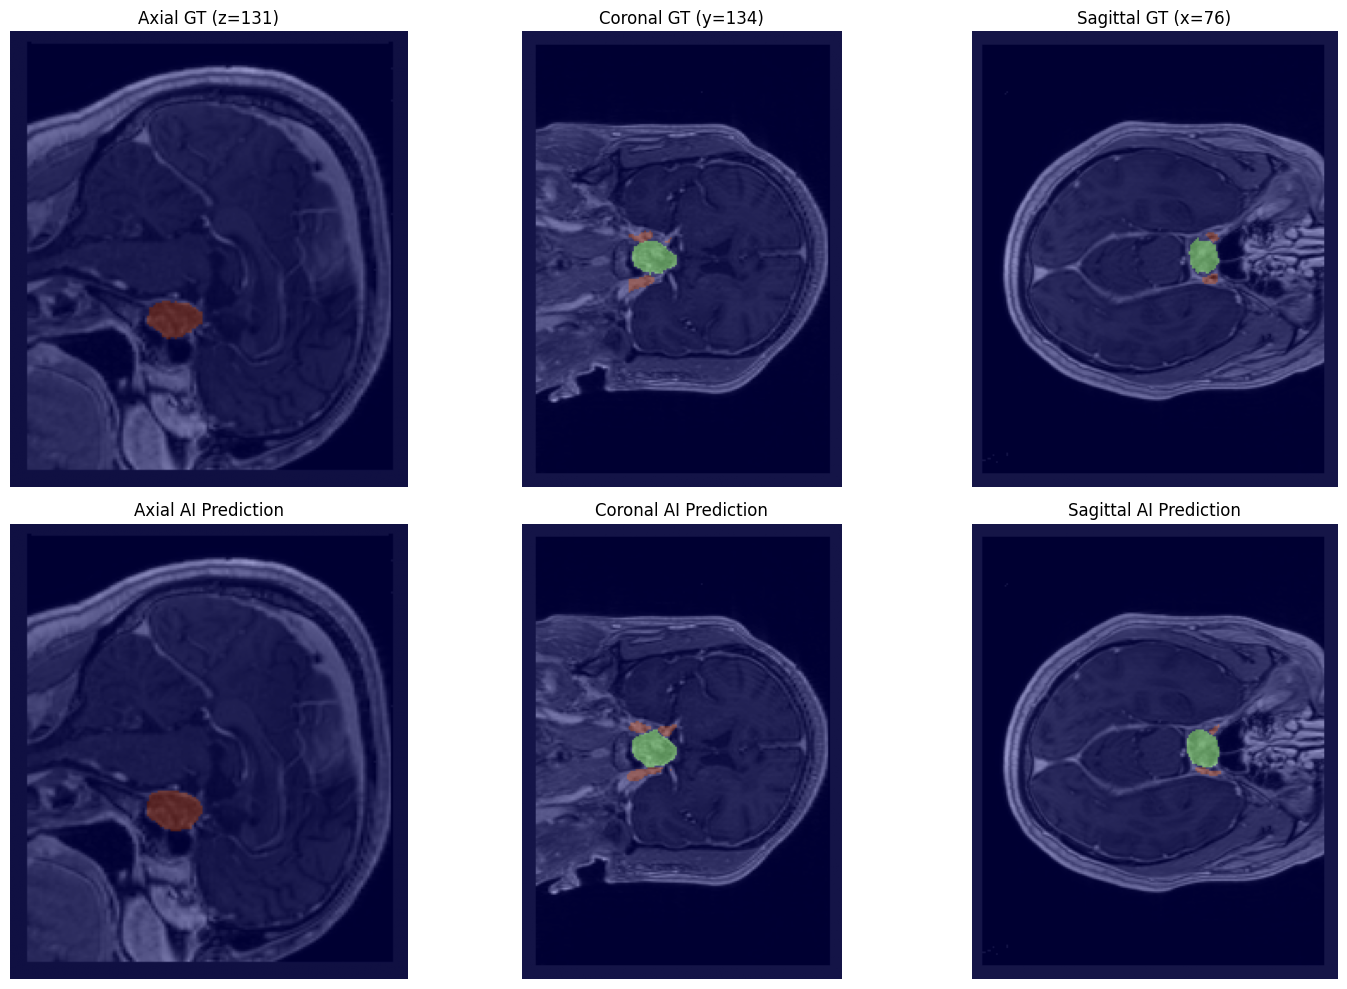

In [3]:
import matplotlib.pyplot as plt

# Take the first validation case
sample = torch.load(val_files[0], map_location="cpu", weights_only=False)
img = sample["image"].unsqueeze(0).to(device)
gt = sample["label"].squeeze().numpy()

with torch.inference_mode():
    logits = sliding_window_inference(img, (128, 128, 128), 1, model, overlap=0.5, mode="gaussian")
    pred = torch.argmax(logits, dim=1, keepdim=True).cpu()
    cleaned = clean_carotid(clean_tumor(pred)).squeeze().numpy()

mri = sample["image"][0].numpy()

# Find slice with maximum tumor presence
tumor_slices = np.where(gt == 1)
z_mid = int(np.median(tumor_slices[0]))
y_mid = int(np.median(tumor_slices[1]))
x_mid = int(np.median(tumor_slices[2]))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
# Ground Truth
axes[0, 0].imshow(mri[z_mid, :, :], cmap="gray"); axes[0, 0].imshow(gt[z_mid, :, :], cmap="jet", alpha=0.4); axes[0, 0].set_title(f"Axial GT (z={z_mid})")
axes[0, 1].imshow(mri[:, y_mid, :], cmap="gray"); axes[0, 1].imshow(gt[:, y_mid, :], cmap="jet", alpha=0.4); axes[0, 1].set_title(f"Coronal GT (y={y_mid})")
axes[0, 2].imshow(mri[:, :, x_mid], cmap="gray"); axes[0, 2].imshow(gt[:, :, x_mid], cmap="jet", alpha=0.4); axes[0, 2].set_title(f"Sagittal GT (x={x_mid})")

# AI Prediction
axes[1, 0].imshow(mri[z_mid, :, :], cmap="gray"); axes[1, 0].imshow(cleaned[z_mid, :, :], cmap="jet", alpha=0.4); axes[1, 0].set_title("Axial AI Prediction")
axes[1, 1].imshow(mri[:, y_mid, :], cmap="gray"); axes[1, 1].imshow(cleaned[:, y_mid, :], cmap="jet", alpha=0.4); axes[1, 1].set_title("Coronal AI Prediction")
axes[1, 2].imshow(mri[:, :, x_mid], cmap="gray"); axes[1, 2].imshow(cleaned[:, :, x_mid], cmap="jet", alpha=0.4); axes[1, 2].set_title("Sagittal AI Prediction")

for ax in axes.flat: ax.axis("off")
plt.tight_layout()
plt.savefig("pituitary_gold_80ep_visual.png", dpi=200, bbox_inches="tight")
print("Saved visualization to pituitary_gold_80ep_visual.png")

Saved visualization to pituitary_dual_sota_visual.png


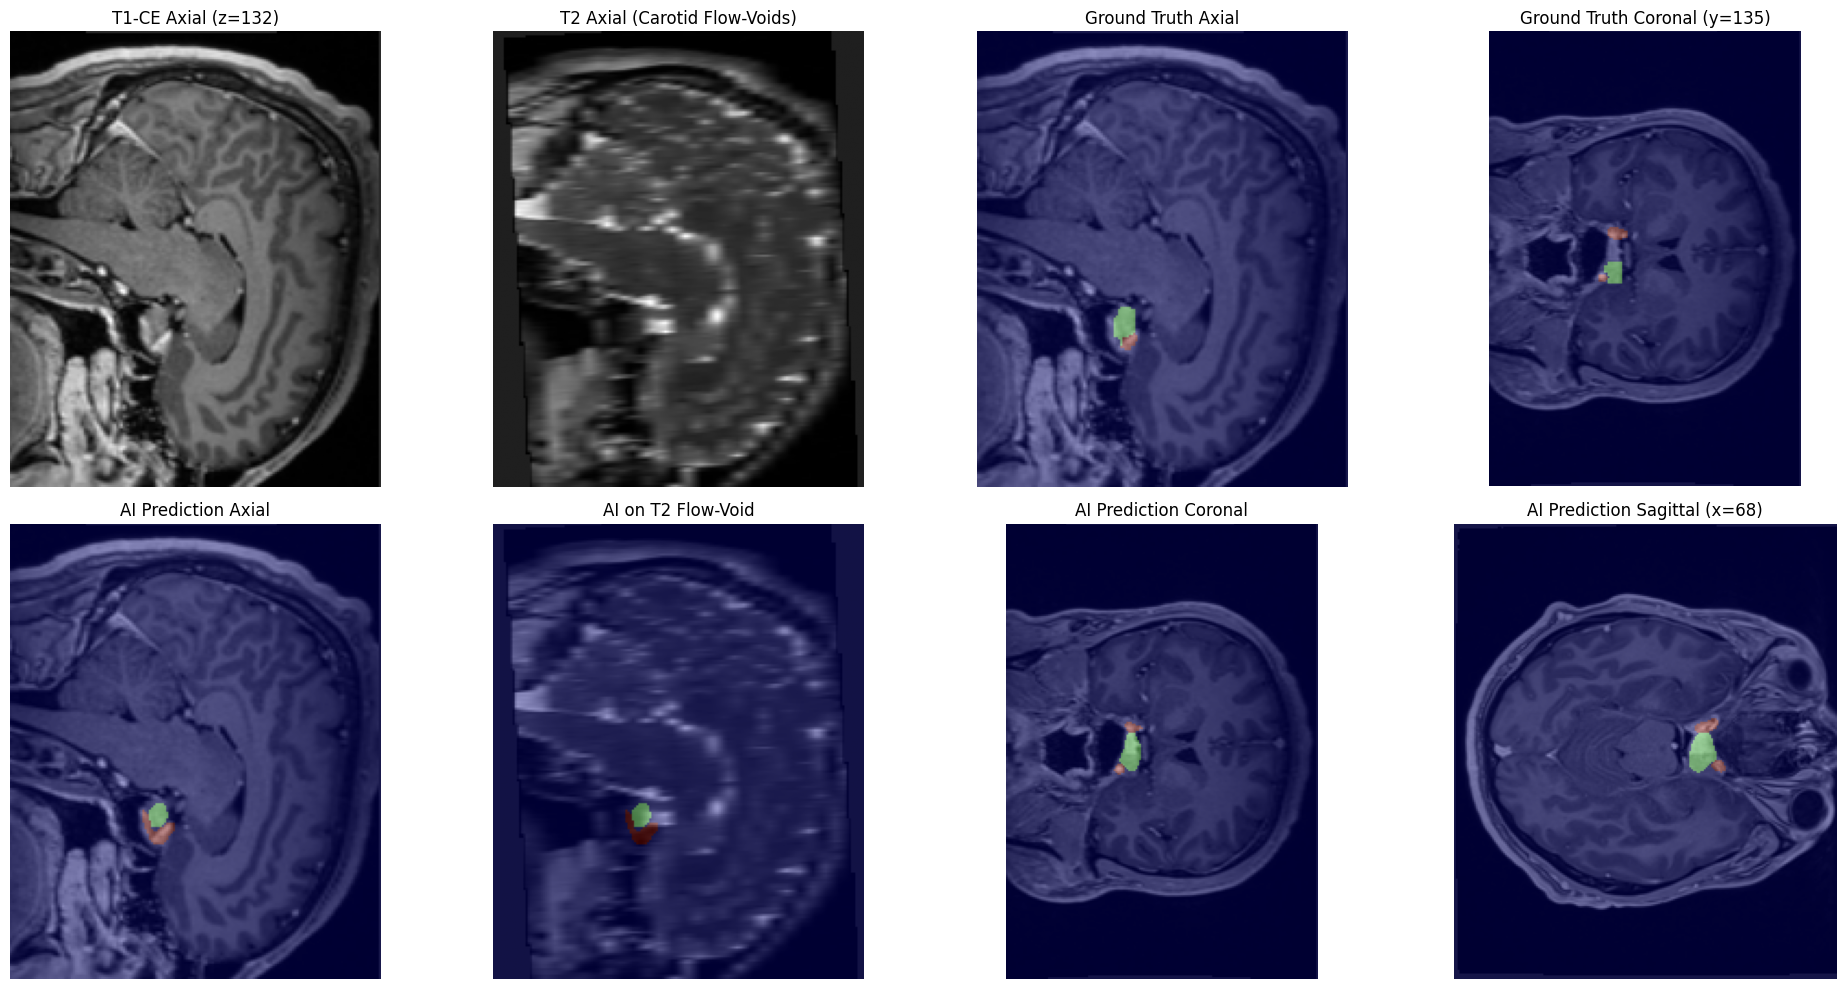

In [2]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference
from monai.transforms import KeepLargestConnectedComponent

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/home/23bq1a4293/Personal/project/seg_data/pit_adv/pituitary_dual_output/best_pituitary_dual_sota.pth"
PROCESSED_DIR = "/home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_dual_1mm"

# Load Model
model = SegResNet(
    spatial_dims=3, in_channels=2, out_channels=3,
    init_filters=32, blocks_down=[1, 2, 2, 4], blocks_up=[1, 1, 1], dropout_prob=0.2
).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=False))
model.eval()

# Val split (seed 42)
all_files = sorted(glob.glob(os.path.join(PROCESSED_DIR, "*.pt")))
torch.manual_seed(42)
perm = torch.randperm(len(all_files)).tolist()
val_files = [all_files[i] for i in perm[80:]]

clean_tumor = KeepLargestConnectedComponent(applied_labels=[1], num_components=1)
clean_carotid = KeepLargestConnectedComponent(applied_labels=[2], num_components=2)

sample = torch.load(val_files[0], map_location="cpu", weights_only=False)
# Convert half-precision to float32:
img = sample["image"].unsqueeze(0).float().to(device)
gt = sample["label"].squeeze().numpy()

with torch.inference_mode():
    logits = sliding_window_inference(img, (128, 128, 128), 1, model, overlap=0.5, mode="gaussian")
    pred = torch.argmax(logits, dim=1, keepdim=True).cpu()
    cleaned = clean_carotid(clean_tumor(pred)).squeeze().numpy()

t1 = sample["image"][0].float().numpy()
t2 = sample["image"][1].float().numpy()

# Tumor slice
tumor_slices = np.where(gt == 1)
z = int(np.median(tumor_slices[0]))
y = int(np.median(tumor_slices[1]))
x = int(np.median(tumor_slices[2]))

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Row 1: Inputs & Ground Truth
axes[0, 0].imshow(t1[z, :, :], cmap="gray"); axes[0, 0].set_title(f"T1-CE Axial (z={z})")
axes[0, 1].imshow(t2[z, :, :], cmap="gray"); axes[0, 1].set_title("T2 Axial (Carotid Flow-Voids)")
axes[0, 2].imshow(t1[z, :, :], cmap="gray"); axes[0, 2].imshow(gt[z, :, :], cmap="jet", alpha=0.4); axes[0, 2].set_title("Ground Truth Axial")
axes[0, 3].imshow(t1[:, y, :], cmap="gray"); axes[0, 3].imshow(gt[:, y, :], cmap="jet", alpha=0.4); axes[0, 3].set_title(f"Ground Truth Coronal (y={y})")

# Row 2: AI Predictions
axes[1, 0].imshow(t1[z, :, :], cmap="gray"); axes[1, 0].imshow(cleaned[z, :, :], cmap="jet", alpha=0.4); axes[1, 0].set_title("AI Prediction Axial")
axes[1, 1].imshow(t2[z, :, :], cmap="gray"); axes[1, 1].imshow(cleaned[z, :, :], cmap="jet", alpha=0.4); axes[1, 1].set_title("AI on T2 Flow-Void")
axes[1, 2].imshow(t1[:, y, :], cmap="gray"); axes[1, 2].imshow(cleaned[:, y, :], cmap="jet", alpha=0.4); axes[1, 2].set_title("AI Prediction Coronal")
axes[1, 3].imshow(t1[:, :, x], cmap="gray"); axes[1, 3].imshow(cleaned[:, :, x], cmap="jet", alpha=0.4); axes[1, 3].set_title(f"AI Prediction Sagittal (x={x})")

for ax in axes.flat: ax.axis("off")
plt.tight_layout()
plt.savefig("pituitary_dual_sota_visual.png", dpi=200, bbox_inches="tight")
print("Saved visualization to pituitary_dual_sota_visual.png")

In [1]:
import glob
import os
import random
from monai.networks.nets import SegResNet
import numpy as np
import scipy.ndimage as ndi
import torch
from torch.amp import autocast

# Matplotlib headless backend
import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt

DATA_DIR = (
    '/home/23bq1a4293/Personal/project/seg_data/pit_adv/processed_sella_05mm'
)
CKPT_PATH = '/home/23bq1a4293/Personal/project/seg_data/pit_adv/pituitary_sella_zoom_output/best_pituitary_sella_zoom_05mm.pth'
OUT_PNG = '/home/23bq1a4293/Personal/project/IMAGE_SEGMENTATION/pit_adv/sella_zoom_sota_visual.png'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def compute_dice(pred, gt):
  inter = np.logical_and(pred, gt).sum()
  tot = pred.sum() + gt.sum()
  return 1.0 if tot == 0 else float(2.0 * inter / (tot + 1e-6))


def clean_carotids(pred_mask, min_voxels=50):
  carotids = pred_mask == 2
  if not np.any(carotids):
    return pred_mask
  labeled, num = ndi.label(carotids)
  sizes = np.bincount(labeled.ravel())
  cleaned = np.copy(pred_mask)
  for i in range(1, num + 1):
    if sizes[i] < min_voxels:
      cleaned[labeled == i] = 0
  return cleaned


def main():
  print('Loading best 0.5mm Sella-Zoom Checkpoint...')
  ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
  state_dict = ckpt['model_state_dict'] if 'model_state_dict' in ckpt else ckpt

  model = SegResNet(
      spatial_dims=3,
      in_channels=2,
      out_channels=3,
      init_filters=32,
      blocks_down=(1, 2, 2, 4),
      blocks_up=(1, 1, 1),
  ).to(DEVICE)
  model.load_state_dict(state_dict)
  model.eval()

  all_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.pt')))
  random.seed(42)
  shuffled = list(all_files)
  random.shuffle(shuffled)
  val_files = shuffled[80:]  # Unseen validation set

  print(f'Evaluating across {len(val_files)} unseen validation cases...')
  tumor_dices, carotid_dices = [], []
  best_sample = None
  highest_dice = -1.0

  with torch.no_grad():
    for f in val_files:
      data = torch.load(f)
      img = data['image'].float()  # [2, 160, 160, 160]
      gt = data['label'].long().squeeze().numpy()

      # Center crop 128^3
      _, D, H, W = img.shape
      sd, sh, sw = (D - 128) // 2, (H - 128) // 2, (W - 128) // 2
      img_crop = (
          img[:, sd : sd + 128, sh : sh + 128, sw : sw + 128]
          .unsqueeze(0)
          .to(DEVICE)
      )
      gt_crop = gt[sd : sd + 128, sh : sh + 128, sw : sw + 128]

      with autocast('cuda'):
        logits = model(img_crop)
        pred = torch.argmax(logits, dim=1).squeeze().cpu().numpy()

      cleaned_pred = clean_carotids(pred, min_voxels=50)

      td = compute_dice(cleaned_pred == 1, gt_crop == 1)
      cd = compute_dice(cleaned_pred == 2, gt_crop == 2)
      md = (td + cd) / 2.0

      tumor_dices.append(td)
      carotid_dices.append(cd)

      if md > highest_dice:
        highest_dice = md
        best_sample = (
            data['case_id'],
            img_crop[0].cpu().numpy(),
            gt_crop,
            cleaned_pred,
            td,
            cd,
        )

  print('=' * 70)
  print(
      f'SELLA-ZOOM 0.5mm VALIDATION BENCHMARK ({len(val_files)} unseen'
      ' patients):'
  )
  print(f'  - Pituitary Tumor Mean Dice:    {np.mean(tumor_dices):.4f}')
  print(f'  - Bilateral Carotids Mean Dice: {np.mean(carotid_dices):.4f}')
  print(
      '  - Overall SOTA Mean Dice:      '
      f' {(np.mean(tumor_dices) + np.mean(carotid_dices)) / 2.0:.4f}'
  )
  print('=' * 70)

  # Render high-resolution multi-planar slices
  case_id, img_v, gt_v, pred_v, td, cd = best_sample
  t1_v = img_v[0]  # T1-CE
  t2_v = img_v[1]  # T2

  # Center on the tumor
  coords = np.where(gt_v == 1)
  if len(coords[0]) > 0:
    cz, cy, cx = (
        int(np.mean(coords[0])),
        int(np.mean(coords[1])),
        int(np.mean(coords[2])),
    )
  else:
    cz, cy, cx = 64, 64, 64

  fig, axes = plt.subplots(3, 4, figsize=(18, 13))
  views = [
      ('Axial (Z)', t1_v[cz], t2_v[cz], gt_v[cz], pred_v[cz]),
      ('Coronal (Y)', t1_v[:, cy, :], t2_v[:, cy, :], gt_v[:, cy, :], pred_v[:, cy, :]),
      ('Sagittal (X)', t1_v[:, :, cx], t2_v[:, :, cx], gt_v[:, :, cx], pred_v[:, :, cx]),
  ]

  for r, (view_name, t1_sl, t2_sl, gt_sl, pred_sl) in enumerate(views):
    # T1-CE
    axes[r, 0].imshow(t1_sl, cmap='gray', origin='lower')
    axes[r, 0].set_title(f'{view_name} - T1-CE Native 0.5mm', fontsize=11)
    axes[r, 0].axis('off')

    # T2
    axes[r, 1].imshow(t2_sl, cmap='gray', origin='lower')
    axes[r, 1].set_title(f'{view_name} - T2 Co-Registered', fontsize=11)
    axes[r, 1].axis('off')

    # Ground Truth Overlay (Red = Tumor, Cyan = Carotids)
    axes[r, 2].imshow(t1_sl, cmap='gray', origin='lower')
    gt_rgb = np.zeros((*gt_sl.shape, 4))
    gt_rgb[gt_sl == 1] = [1.0, 0.0, 0.0, 0.55]  # Red: Tumor
    gt_rgb[gt_sl == 2] = [0.0, 1.0, 1.0, 0.70]  # Cyan: Carotids
    axes[r, 2].imshow(gt_rgb, origin='lower')
    axes[r, 2].set_title(f'{view_name} - Ground Truth', fontsize=11)
    axes[r, 2].axis('off')

    # SOTA Prediction Overlay (Green = Tumor, Cyan = Carotids)
    axes[r, 3].imshow(t1_sl, cmap='gray', origin='lower')
    pred_rgb = np.zeros((*pred_sl.shape, 4))
    pred_rgb[pred_sl == 1] = [0.0, 1.0, 0.0, 0.55]  # Green: AI Tumor
    pred_rgb[pred_sl == 2] = [0.0, 1.0, 1.0, 0.70]  # Cyan: AI Carotids
    axes[r, 3].imshow(pred_rgb, origin='lower')
    axes[r, 3].set_title(f'{view_name} - 0.5mm SOTA AI Prediction', fontsize=11)
    axes[r, 3].axis('off')

  plt.suptitle(
      f'Patient {case_id} [0.5mm Sella-Zoom SOTA] | Tumor Dice: {td:.4f} |'
      f' Carotid Dice: {cd:.4f}',
      fontsize=15,
      fontweight='bold',
  )
  plt.tight_layout()
  plt.savefig(OUT_PNG, dpi=300, bbox_inches='tight')
  print(f'Verification visual saved successfully to: {OUT_PNG}')


if __name__ == '__main__':
  main()

/usr/local/pythonEnv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.1.0)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(
I0000 00:00:1793871211.430795  453369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793871211.512611  453369 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793871213.241700  453369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different 

Loading best 0.5mm Sella-Zoom Checkpoint...


/tmp/ipykernel_453369/2452022569.py:45: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(CKPT_PATH, map_location=DEVICE)


Evaluating across 19 unseen validation cases...


/tmp/ipykernel_453369/2452022569.py:72: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  data = torch.load(f)


SELLA-ZOOM 0.5mm VALIDATION BENCHMARK (19 unseen patients):
  - Pituitary Tumor Mean Dice:    0.8192
  - Bilateral Carotids Mean Dice: 0.6699
  - Overall SOTA Mean Dice:       0.7445
Verification visual saved successfully to: /home/23bq1a4293/Personal/project/IMAGE_SEGMENTATION/pit_adv/sella_zoom_sota_visual.png
